<a href="https://colab.research.google.com/github/Kir4Kir4/DSA_23020545_NguyenTungLam/blob/main/MIDTERM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


### Khởi tạo môi trường và Tải dữ liệu
Đầu tiên, chúng ta cần nhập các thư viện phân tích dữ liệu thiết yếu và tải 4 bộ dữ liệu thị trường (BE, DE, ES, SE_3).
Vì đây là bài toán dự báo chuỗi thời gian, hệ thống sẽ tự động nhận diện cột đầu tiên của file dữ liệu là mốc thời gian, sau đó tự động phân tích cú pháp (parse) thành định dạng datetime và thiết lập nó làm chỉ mục (Index) để thuận tiện cho việc truy xuất và vẽ biểu đồ theo trục thời gian.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import os

data_dir = '/content/drive/MyDrive/Colab Notebooks/PEPF_bench/preprocessing/data/raw/deepforkit'
markets = ['BE', 'DE', 'ES', 'SE_3']

raw_data = {}

for market in markets:
    file_path = os.path.join(data_dir, f'{market}.csv')
    df = pd.read_csv(file_path, index_col=0, parse_dates=True)
    raw_data[market] = df


In [11]:
display(raw_data['BE'].head())

display(raw_data['DE'].head())

display(raw_data['ES'].head())

display(raw_data['SE_3'].head())

,Price_DA,Load_DA,Load_AC,Gen_SC,Sol_DA,Won_DA
2015-01-05 00:00:00,36.56,9747.0,10248.0,7903.0,0,155.0
2015-01-05 01:00:00,34.94,9560.0,9844.0,7736.0,0,177.0
2015-01-05 02:00:00,32.19,9086.0,9355.0,7018.0,0,214.0
2015-01-05 03:00:00,28.05,8783.0,9113.0,6830.0,0,250.0
2015-01-05 04:00:00,28.04,8654.0,9094.0,7173.0,0,270.0


,Price_DA,Load_DA,Load_AC,Gen_SC,Sol_DA,Won_DA
2015-01-05 00:00:00,22.34,51003.0,54386.0,0.0,0,11734.0
2015-01-05 01:00:00,17.93,49198.0,51704.0,0.0,0,11873.0
2015-01-05 02:00:00,15.17,47612.0,50362.0,0.0,0,11971.0
2015-01-05 03:00:00,16.38,47273.0,49659.0,0.0,0,12033.0
2015-01-05 04:00:00,17.38,47782.0,50380.0,0.0,0,12139.0


,Price_DA,Load_DA,Load_AC,Gen_SC,Sol_DA,Won_DA
2015-01-01 00:00:00,50.10,26118.0,25385.0,23921.0,17.0,6436.0
2015-01-01 01:00:00,48.10,24934.0,24382.0,23242.0,16.0,5856.0
2015-01-01 02:00:00,47.33,23515.0,22734.0,21878.0,8.0,5454.0
2015-01-01 03:00:00,42.27,22642.0,21286.0,20228.0,2.0,5151.0
2015-01-01 04:00:00,38.41,21785.0,20264.0,19579.0,9.0,4861.0


,Price_DA,Load_DA,Load_AC,Gen_SC,Sol_DA,Won_DA
2015-01-01 00:00:00,27.38,8741.0,9560.0,11727.0,0,1396.0
2015-01-01 01:00:00,23.37,8525.0,9520.0,11730.0,0,1436.0
2015-01-01 02:00:00,19.33,8308.0,9277.0,11711.0,0,1476.0
2015-01-01 03:00:00,17.66,8194.0,9132.0,11705.0,0,1502.0
2015-01-01 04:00:00,17.53,8215.0,9083.0,11725.0,0,1513.0


### Khám phá dữ liệu (EDA) - Kiểm tra chất lượng và Phân phối
Trước khi đưa vào mô hình, ta cần đánh giá tổng quan về hình dạng dữ liệu và xác định số lượng giá trị khuyết thiếu (NaN). Các mô hình học máy không thể xử lý dữ liệu rỗng.
Bên cạnh đó, việc trực quan hóa phân phối của biến mục tiêu (Giá điện) giúp nhận diện các bất thường của dữ liệu, chẳng hạn như hiện tượng giá âm hoặc các đợt giá tăng vọt đột biến (Price Spikes).

--- THỐNG KÊ TỔNG QUAN ---
[BE] Số dòng: 74376, Số cột: 6 | Giá trị thiếu (Max): 0
[DE] Số dòng: 74376, Số cột: 6 | Giá trị thiếu (Max): 0
[ES] Số dòng: 74472, Số cột: 6 | Giá trị thiếu (Max): 0
[SE_3] Số dòng: 74472, Số cột: 6 | Giá trị thiếu (Max): 0


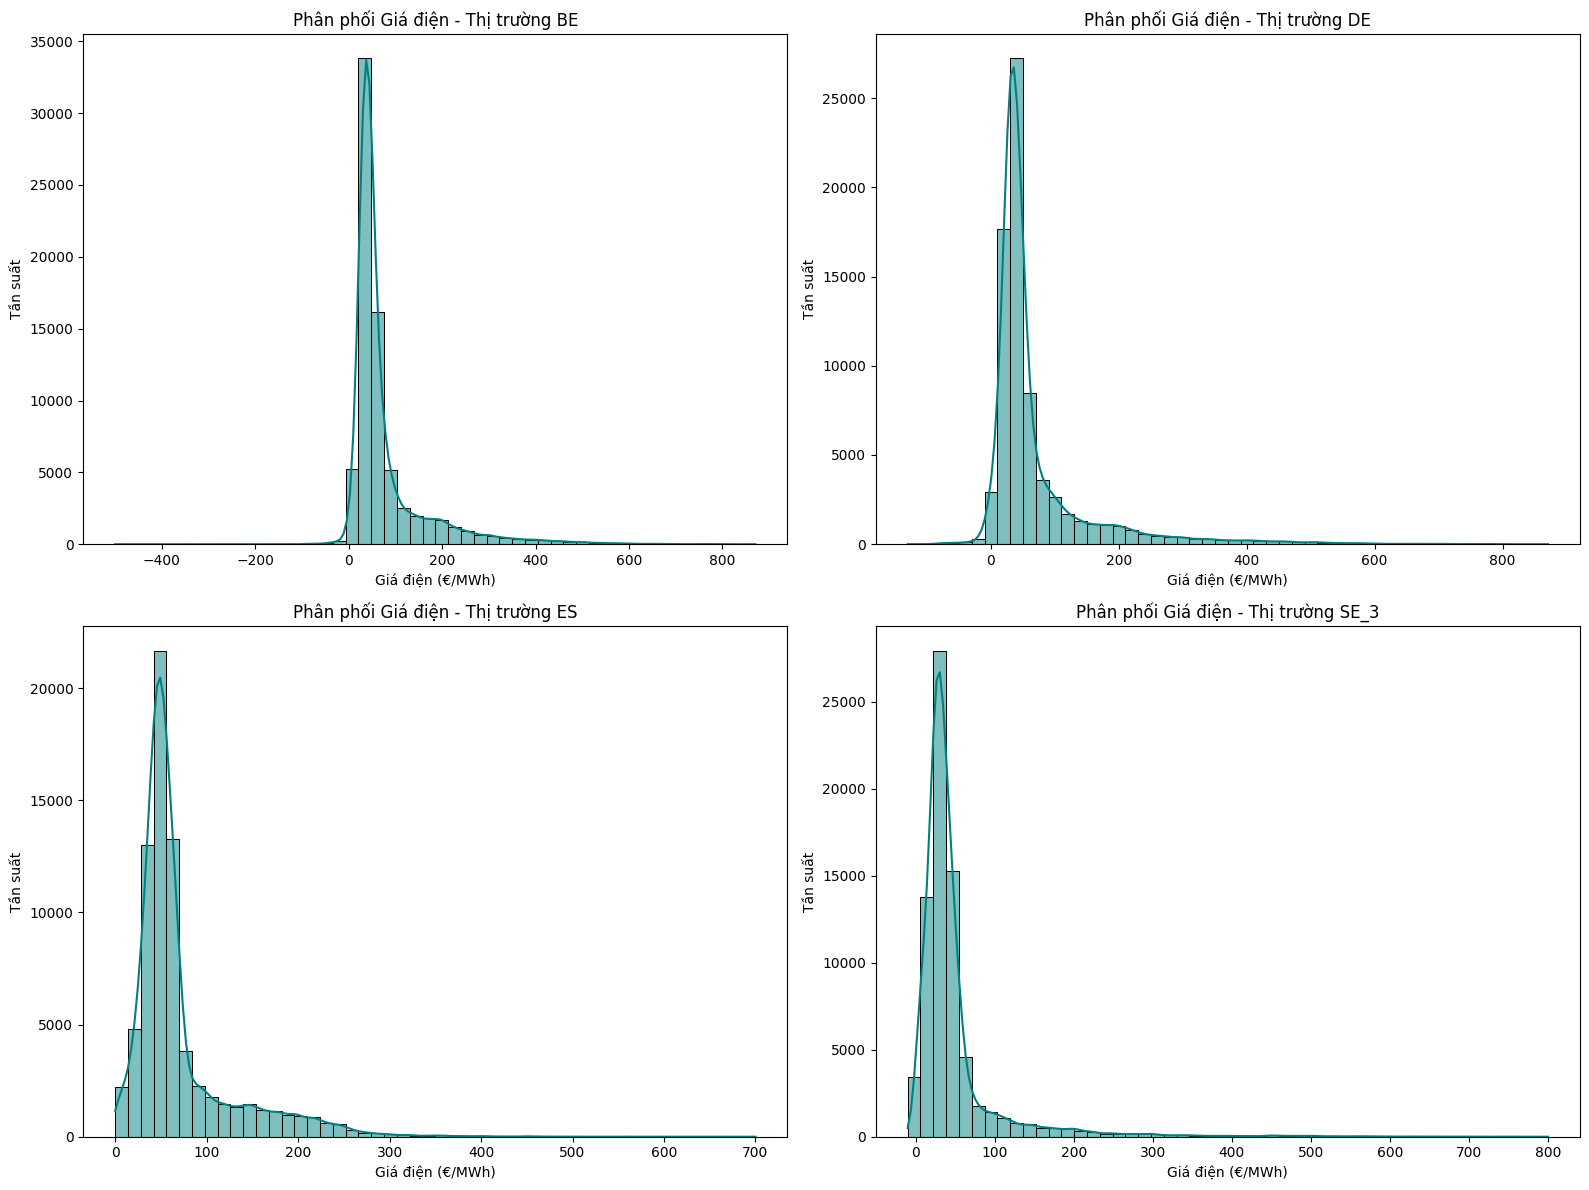

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

print("--- THỐNG KÊ TỔNG QUAN ---")
for idx, market in enumerate(markets):
    df = raw_data[market]
    print(f"[{market}] Số dòng: {df.shape[0]}, Số cột: {df.shape[1]} | Giá trị thiếu (Max): {df.isnull().sum().max()}")

    sns.histplot(df['Price_DA'], bins=50, kde=True, ax=axes[idx], color='teal')
    axes[idx].set_title(f'Phân phối Giá điện - Thị trường {market}')
    axes[idx].set_xlabel('Giá điện (€/MWh)')
    axes[idx].set_ylabel('Tần suất')

plt.tight_layout()
plt.show()

### Tiền xử lý - Điền khuyết thiếu và Trích xuất đặc trưng thời gian
- **Điền khuyết thiếu (Imputation):** Thay vì xóa bỏ các hàng bị thiếu làm đứt gãy chuỗi thời gian, phương pháp nội suy tuyến tính (Linear Interpolation) được sử dụng để duy trì tính liên tục và xu hướng của dữ liệu.
- **Trích xuất đặc trưng (Feature Engineering):** Giá điện có tính chu kỳ mạnh mẽ theo giờ trong ngày và ngày trong tuần. Ta sẽ tách các thông tin ẩn này từ `index` thành các cột đặc trưng riêng lẻ (hour, dayofweek, is_weekend) để thuật toán dễ dàng học được chu kỳ này.

In [13]:
processed_data = {}

for market in markets:
    df = raw_data[market].copy()

    df = df.interpolate(method='linear', limit_direction='both')

    df['hour'] = df.index.hour
    df['dayofweek'] = df.index.dayofweek
    df['month'] = df.index.month
    df['is_weekend'] = df['dayofweek'].apply(lambda x: 1 if x >= 5 else 0)

    processed_data[market] = df

In [14]:
display(processed_data['BE'].head())
print(f"Tổng số cột hiện tại: {processed_data['BE'].shape[1]}")
print(f"Tổng số lượng giá trị rỗng (NaN): {processed_data['BE'].isnull().sum().max()}")

,Price_DA,Load_DA,Load_AC,Gen_SC,Sol_DA,Won_DA,hour,dayofweek,month,is_weekend
2015-01-05 00:00:00,36.56,9747.0,10248.0,7903.0,0,155.0,0,0,1,0
2015-01-05 01:00:00,34.94,9560.0,9844.0,7736.0,0,177.0,1,0,1,0
2015-01-05 02:00:00,32.19,9086.0,9355.0,7018.0,0,214.0,2,0,1,0
2015-01-05 03:00:00,28.05,8783.0,9113.0,6830.0,0,250.0,3,0,1,0
2015-01-05 04:00:00,28.04,8654.0,9094.0,7173.0,0,270.0,4,0,1,0


Tổng số cột hiện tại: 10
Tổng số lượng giá trị rỗng (NaN): 0


### Chuẩn hóa dữ liệu
Các biến số đầu vào có thang đo rất khác nhau (ví dụ: Tổng phụ tải có thể lên tới hàng chục nghìn MW, trong khi sản lượng điện gió chỉ ở mức hàng trăm). Nếu không chuẩn hóa, mô hình có thể bị thiên lệch và ưu tiên các biến có giá trị lớn.
Ta sử dụng `StandardScaler` (Z-score normalization) để đưa các biến dự báo về cùng một phương sai. Lưu ý: Biến mục tiêu `price` được giữ nguyên để kết quả dự báo phản ánh đúng mức giá thực tế.

In [15]:
for market in markets:
    df = processed_data[market]

    features_to_scale = [col for col in df.columns if col != 'Price_DA']

    # Thực hiện chuẩn hóa
    scaler = StandardScaler()
    df[features_to_scale] = scaler.fit_transform(df[features_to_scale])

    processed_data[market] = df

### Phân tích Tương quan
Để kết thúc pha Khám phá, ma trận tương quan  được áp dụng để đánh giá mối quan hệ tuyến tính giữa các biến.
Phân tích này giúp xác định những yếu tố năng lượng nào (ví dụ: Năng lượng tái tạo, Phụ tải) có tác động mạnh nhất đến biến động Giá điện.

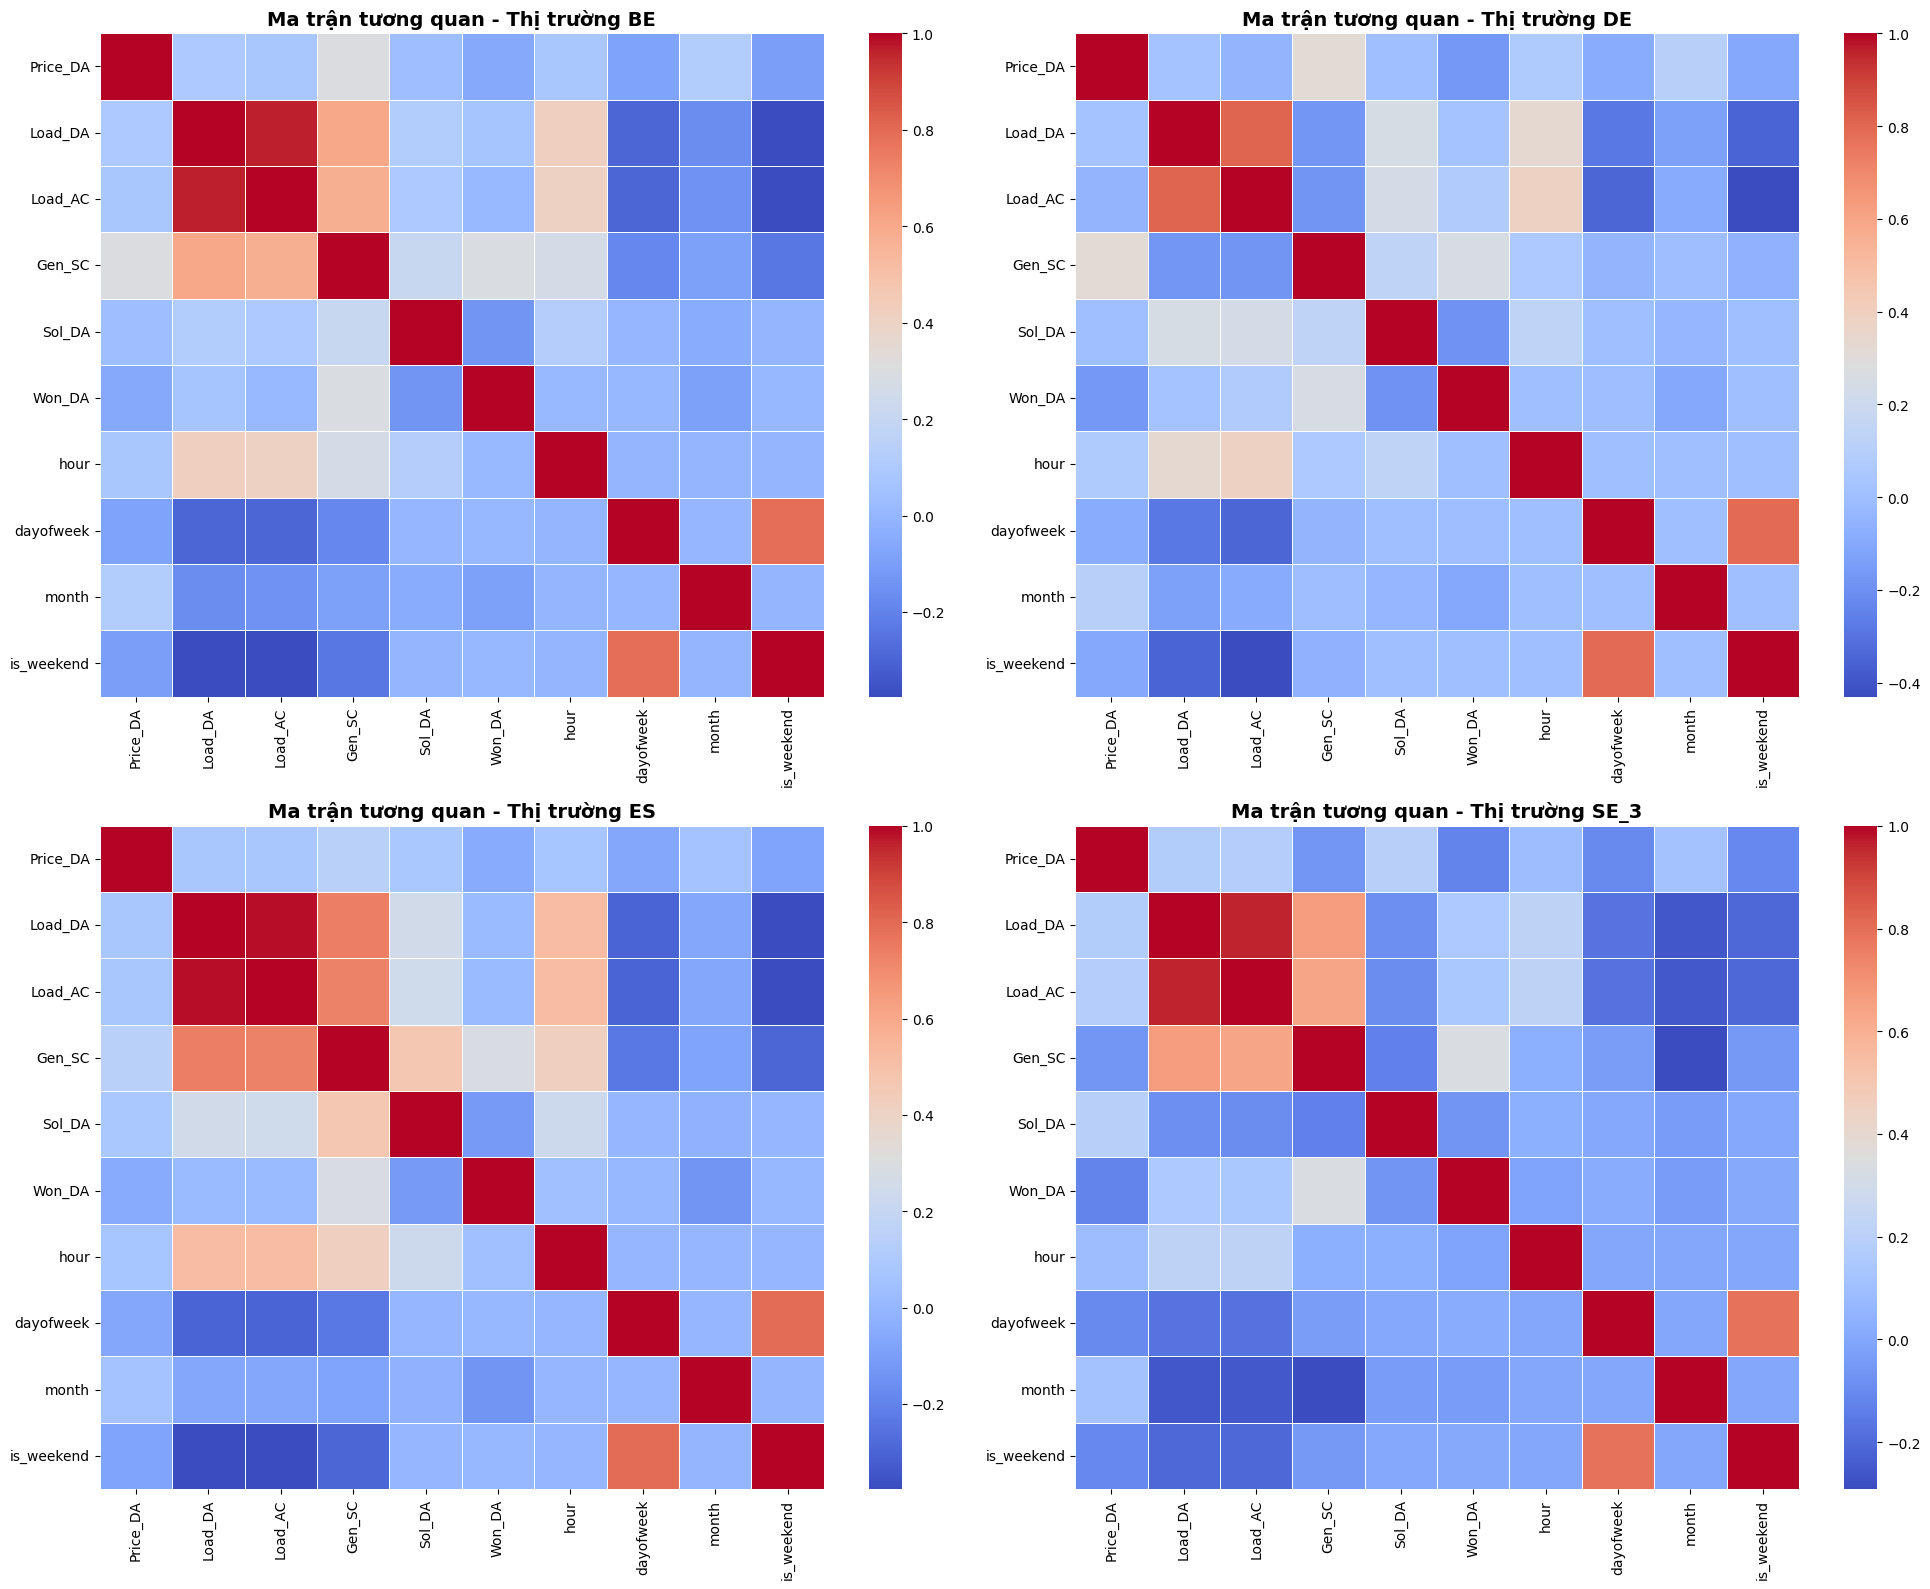

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
axes = axes.flatten()


for idx, market in enumerate(markets):
    corr_matrix = processed_data[market].corr()

    sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt=".2f", linewidths=0.5, ax=axes[idx])
    axes[idx].set_title(f'Ma trận tương quan - Thị trường {market}', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### Hồi quy
Thay vì sử dụng mạng nơ-ron phức tạp ngay từ đầu, ta thiết lập các đường cơ sở (baselines) bằng phương pháp học máy cổ điển để dự báo mức giá điện liên tục.
1. **Phân chia Dữ liệu:** lấy 80% dữ liệu quá khứ để huấn luyện và 20% dữ liệu cuối cùng (tương đương khoảng 1 năm) để kiểm thử.
2. **Mô hình triển khai:**
   - **Linear Regression :** Mô hình cơ bản nhất để tìm mối quan hệ tuyến tính.
   - **Random Forest Regressor:** Mô hình phi tuyến tính mạnh mẽ, có khả năng bắt được các quy luật phức tạp và xử lý tốt hiện tượng đa cộng tuyến giữa các biến.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

regression_metrics = {}
rf_models = {} # Lưu lại mô hình RF để xem độ quan trọng của biến

for market in markets:
    print(f"Đang xử lý thị trường [{market}]...")
    df = processed_data[market]

    X = df.drop(columns=['Price_DA'])
    y = df['Price_DA']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

    # Linear Regression
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)
    lr_preds = lr_model.predict(X_test)
    lr_mae = mean_absolute_error(y_test, lr_preds)

    # Huấn luyện Random Forest
    rf_model = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)
    rf_model.fit(X_train, y_train)
    rf_preds = rf_model.predict(X_test)
    rf_mae = mean_absolute_error(y_test, rf_preds)

    regression_metrics[market] = {'Linear_MAE': lr_mae, 'RandomForest_MAE': rf_mae}
    rf_models[market] = rf_model

    print(f"  -> Linear Regression MAE : {lr_mae:.2f} €/MWh")
    print(f"  -> Random Forest MAE     : {rf_mae:.2f} €/MWh\n")

Đang xử lý thị trường [BE]...
  -> Linear Regression MAE : 165.37 €/MWh
  -> Random Forest MAE     : 162.40 €/MWh

Đang xử lý thị trường [DE]...
  -> Linear Regression MAE : 151.82 €/MWh
  -> Random Forest MAE     : 150.33 €/MWh

Đang xử lý thị trường [ES]...
  -> Linear Regression MAE : 110.15 €/MWh
  -> Random Forest MAE     : 105.62 €/MWh

Đang xử lý thị trường [SE_3]...
  -> Linear Regression MAE : 81.65 €/MWh
  -> Random Forest MAE     : 84.26 €/MWh



### Feature Importance

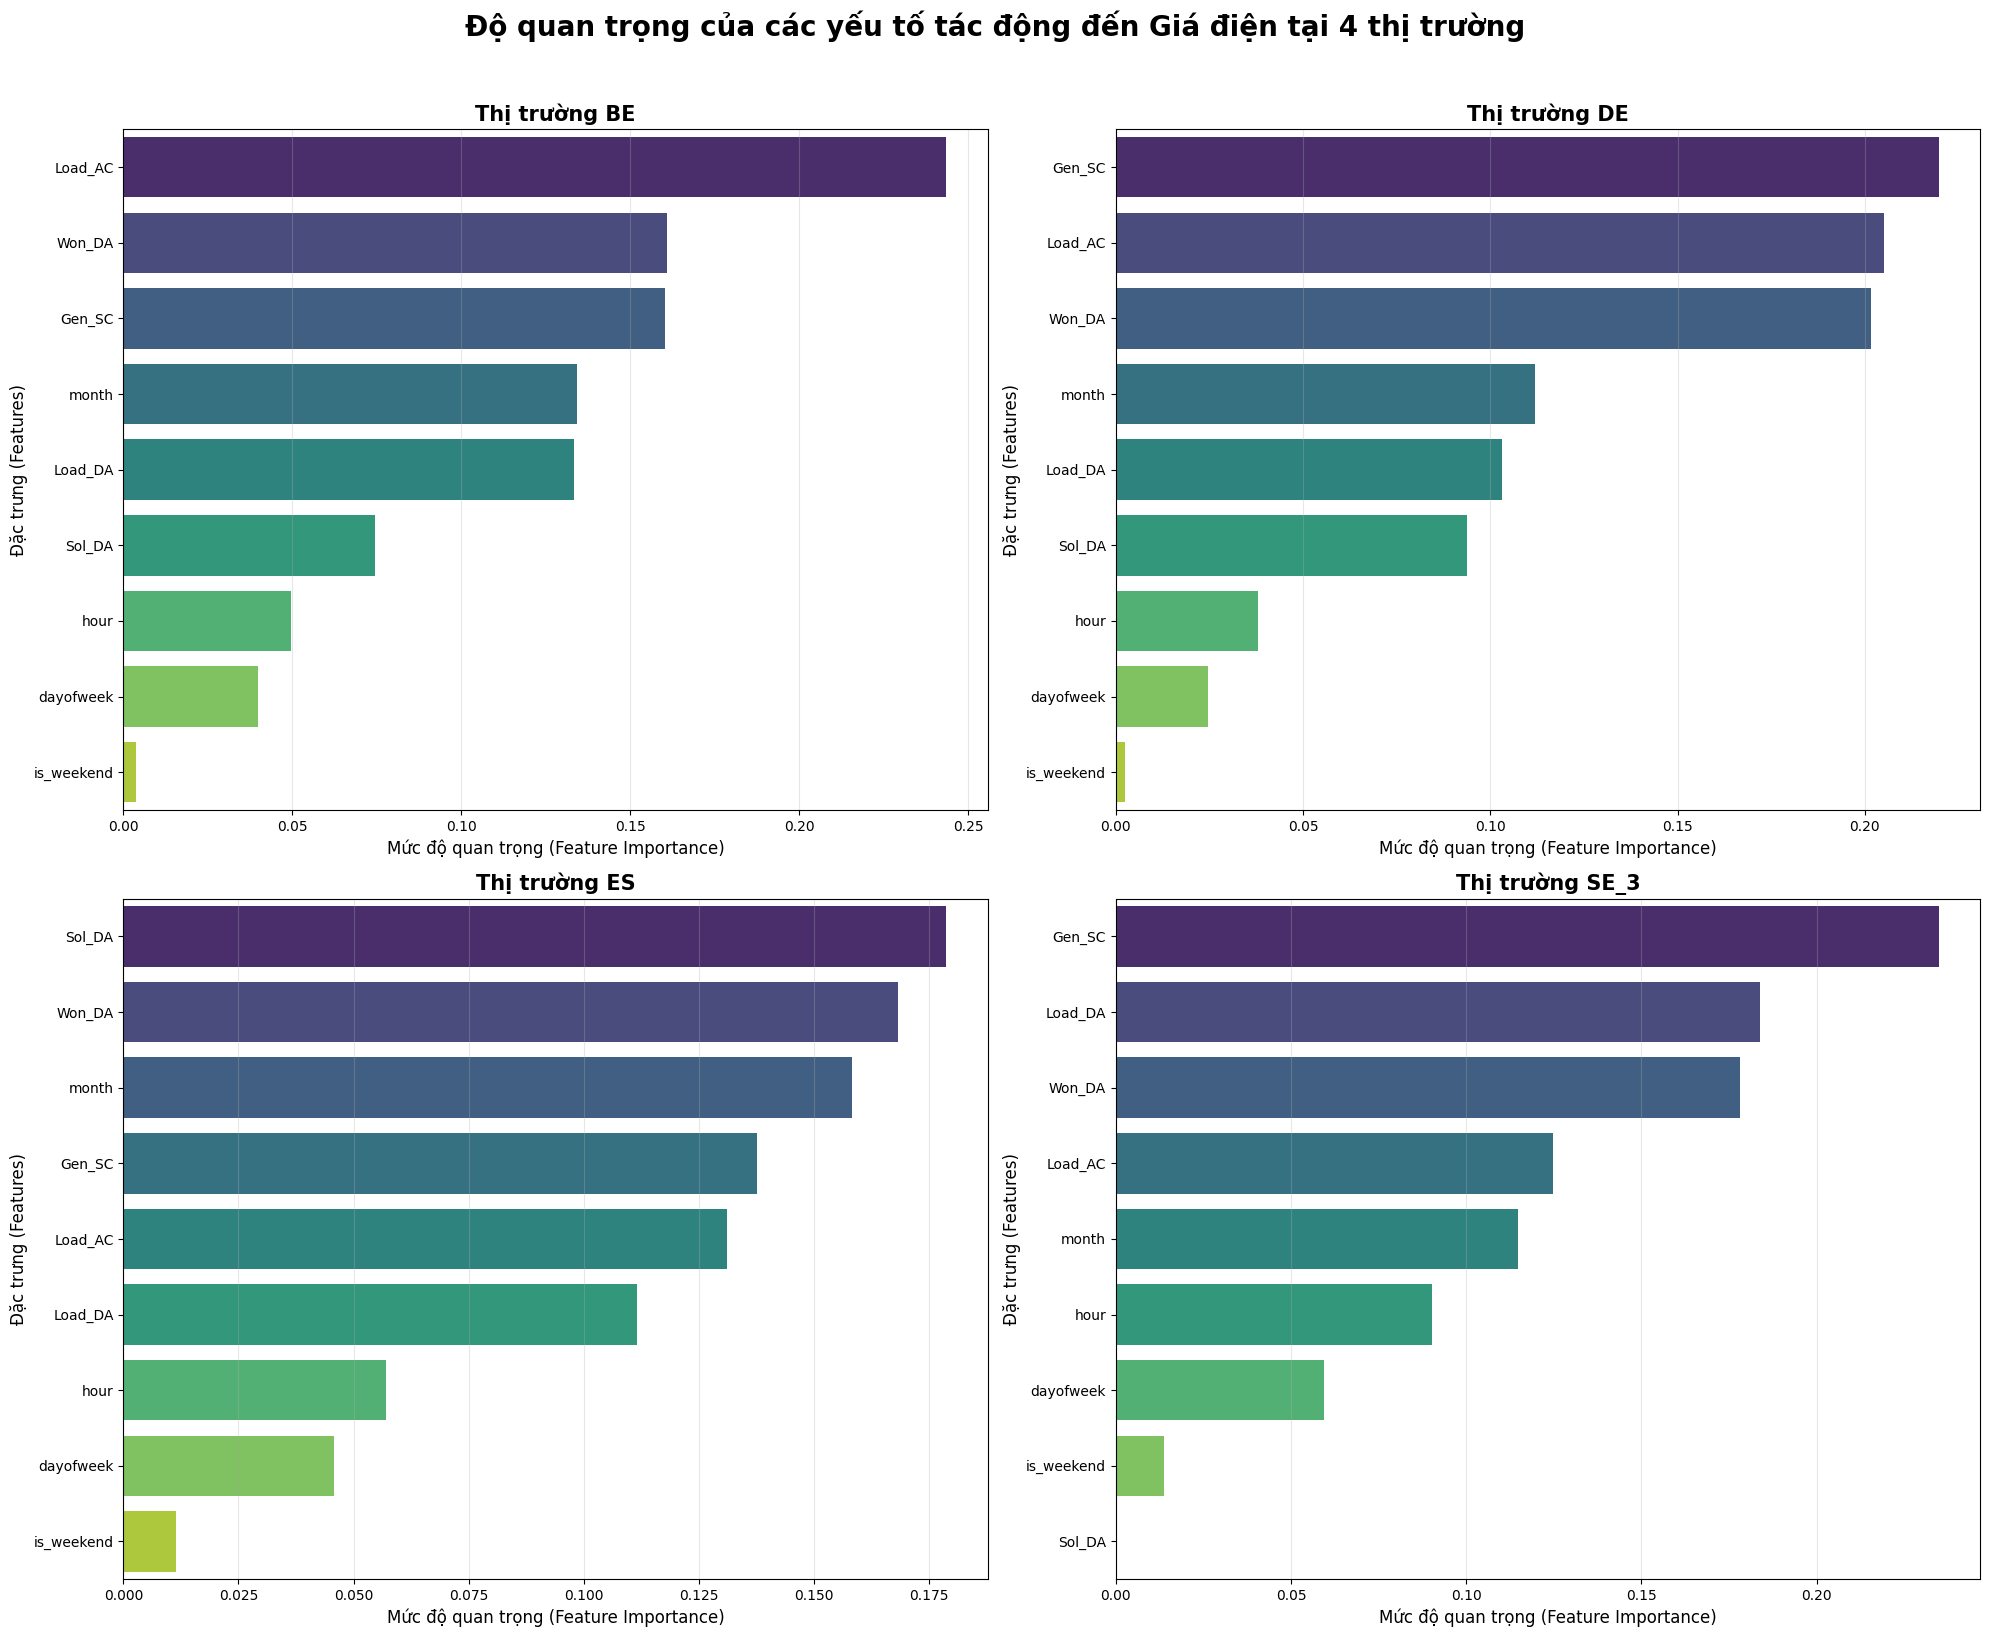

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
axes = axes.flatten()

for idx, market in enumerate(markets):
    rf_model = rf_models[market]
    features = processed_data[market].drop(columns=['Price_DA']).columns
    importances = rf_model.feature_importances_

    indices = np.argsort(importances)[::-1]

    # Vẽ biểu đồ lên trục tương ứng
    sns.barplot(
        x=importances[indices],
        y=features[indices],
        palette="viridis",
        hue=features[indices],
        legend=False,
        ax=axes[idx]
    )
    axes[idx].set_title(f'Thị trường {market}', fontsize=15, fontweight='bold')
    axes[idx].set_xlabel('Mức độ quan trọng (Feature Importance)', fontsize=12)
    axes[idx].set_ylabel('Đặc trưng (Features)', fontsize=12)
    axes[idx].grid(axis='x', alpha=0.3)

plt.suptitle('Độ quan trọng của các yếu tố tác động đến Giá điện tại 4 thị trường', fontsize=20, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Bài toán Phân lớp - Dự đoán Price Spikes
Biến mục tiêu ở đây không còn là giá trị liên tục, mà là một biến nhị phân (0 hoặc 1). Ta sẽ định nghĩa một **"Price Spike" (Sự cố tăng vọt giá)** là khi giá điện vượt quá **phân vị thứ 90 (Top 10% mức giá cao nhất)** của thị trường đó.
Vì Spikes là những sự kiện hiếm gặp (chỉ chiếm 10% dữ liệu), đây là bài toán phân lớp mất cân bằng (Imbalanced Classification).
- **Mô hình triển khai:** Logistic Regression và XGBoost Classifier.
- **Thước đo đánh giá:** Thay vì Accuracy, ta tập trung vào **Recall (Độ phủ)** - khả năng "bắt" được bao nhiêu sự cố Spike, và **F1-Score** để cân bằng.

In [20]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

classification_models = {}

for market in markets:
    print(f"\n{'='*40}")
    print(f" THỊ TRƯỜNG: {market}")
    print(f"{'='*40}")

    df = processed_data[market].copy()

    threshold = df['Price_DA'].quantile(0.90)
    df['is_spike'] = (df['Price_DA'] >= threshold).astype(int)

    print(f"Ngưỡng xác định Spike (Top 10%): >= {threshold:.2f} €/MWh")

    X = df.drop(columns=['Price_DA', 'is_spike'])
    y = df['is_spike']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

    # 4. Huấn luyện Logistic Regression
    log_reg = LogisticRegression(class_weight='balanced', max_iter=1000)
    log_reg.fit(X_train, y_train)
    lr_preds = log_reg.predict(X_test)

    # 5. Huấn luyện XGBoost Classifier
    xgb_model = XGBClassifier(n_estimators=100, scale_pos_weight=9.0, random_state=42, n_jobs=-1)
    xgb_model.fit(X_train, y_train)
    xgb_preds = xgb_model.predict(X_test)

    classification_models[market] = {'Logistic': log_reg, 'XGBoost': xgb_model}

    # 6. In Báo cáo đánh giá
    print("\n[Báo cáo Hiệu suất XGBoost Classifier]")
    print(classification_report(y_test, xgb_preds, target_names=['Bình thường (0)', 'Spike (1)']))


 THỊ TRƯỜNG: BE
Ngưỡng xác định Spike (Top 10%): >= 183.38 €/MWh

[Báo cáo Hiệu suất XGBoost Classifier]
                 precision    recall  f1-score   support

Bình thường (0)       0.53      1.00      0.69      7813
      Spike (1)       0.58      0.00      0.00      7063

       accuracy                           0.53     14876
      macro avg       0.55      0.50      0.35     14876
   weighted avg       0.55      0.53      0.36     14876


 THỊ TRƯỜNG: DE
Ngưỡng xác định Spike (Top 10%): >= 165.19 €/MWh

[Báo cáo Hiệu suất XGBoost Classifier]
                 precision    recall  f1-score   support

Bình thường (0)       0.52      1.00      0.69      7755
      Spike (1)       0.72      0.01      0.02      7121

       accuracy                           0.52     14876
      macro avg       0.62      0.50      0.35     14876
   weighted avg       0.62      0.52      0.37     14876


 THỊ TRƯỜNG: ES
Ngưỡng xác định Spike (Top 10%): >= 153.53 €/MWh

[Báo cáo Hiệu suất XGBoost Clas

--- MA TRẬN NHẦM LẪN (XGBOOST) - 4 THỊ TRƯỜNG ---


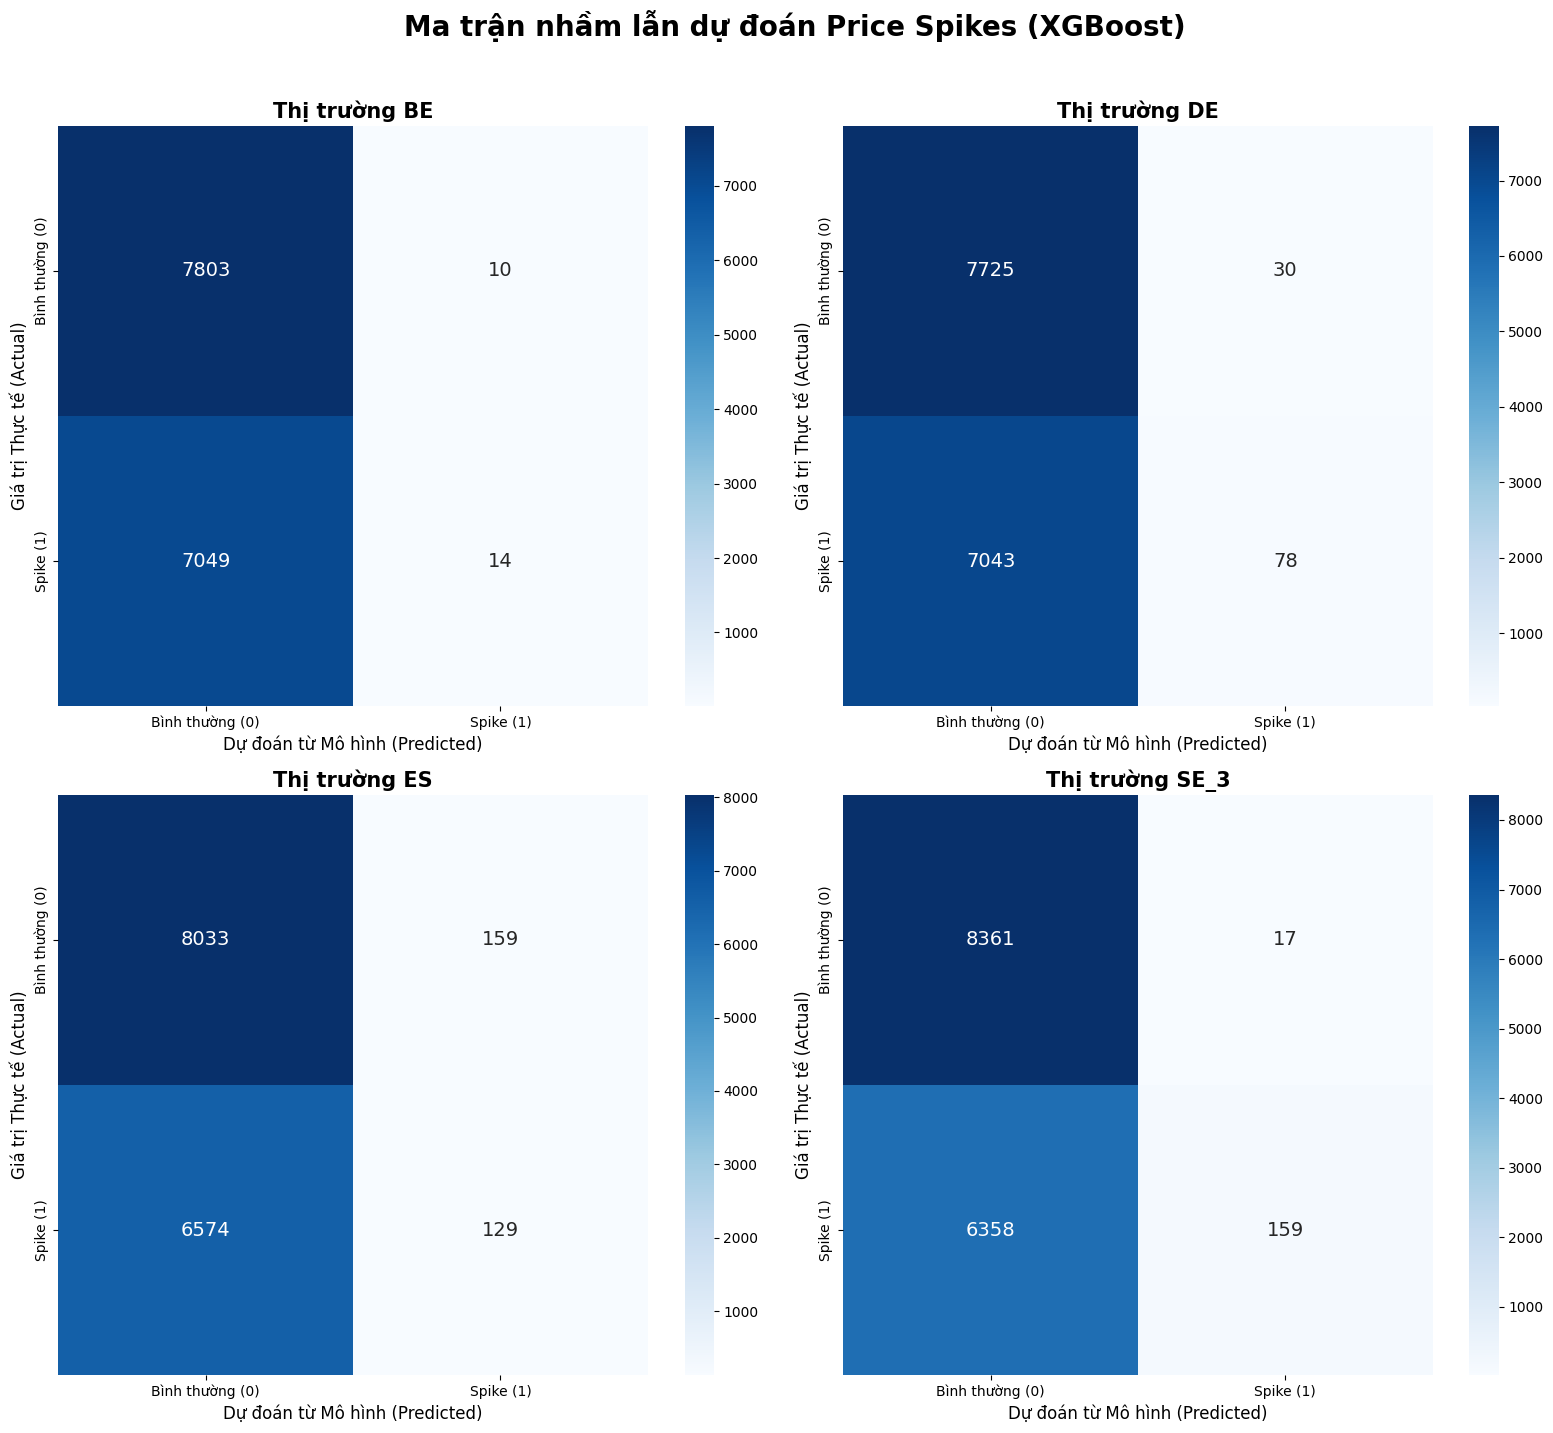

In [21]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()

print("--- MA TRẬN NHẦM LẪN (XGBOOST) - 4 THỊ TRƯỜNG ---")

for idx, market in enumerate(markets):
    df = processed_data[market].copy()
    threshold = df['Price_DA'].quantile(0.90)
    df['is_spike'] = (df['Price_DA'] >= threshold).astype(int)

    X = df.drop(columns=['Price_DA', 'is_spike'])
    y = df['is_spike']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

    # Lấy mô hình XGBoost đã huấn luyện
    xgb_model = classification_models[market]['XGBoost']
    xgb_preds = xgb_model.predict(X_test)

    # Tính ma trận nhầm lẫn
    cm = confusion_matrix(y_test, xgb_preds)

    # Heatmap
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Bình thường (0)', 'Spike (1)'],
                yticklabels=['Bình thường (0)', 'Spike (1)'],
                annot_kws={"size": 14})
    axes[idx].set_title(f'Thị trường {market}', fontsize=15, fontweight='bold')
    axes[idx].set_xlabel('Dự đoán từ Mô hình (Predicted)', fontsize=12)
    axes[idx].set_ylabel('Giá trị Thực tế (Actual)', fontsize=12)

plt.suptitle('Ma trận nhầm lẫn dự đoán Price Spikes (XGBoost)', fontsize=20, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [13]:
%cd /content/drive/MyDrive/Colab Notebooks/PEPF_bench/preprocessing
!pip install -r ../requirements.txt
!python script_generate_Deepforkit_entsoe_dataset.py

/content/drive/MyDrive/Colab Notebooks/PEPF_bench/preprocessing
ERROR: Could not open requirements file: [Errno 2] No such file or directory: '../requirements.txt'
fixed_nan (using d-1 value) for FUTU__load_f in dt: 2023-07-01 00:00:00
fixed_nan (using d-1 value) for FUTU__load_f in dt: 2023-07-01 01:00:00
fixed_nan (using d-1 value) for FUTU__load_f in dt: 2023-07-01 02:00:00
fixed_nan (using d-1 value) for FUTU__load_f in dt: 2023-07-01 03:00:00
fixed_nan (using d-1 value) for FUTU__load_f in dt: 2023-07-01 04:00:00
fixed_nan (using d-1 value) for FUTU__load_f in dt: 2023-07-01 05:00:00
fixed_nan (using d-1 value) for FUTU__load_f in dt: 2023-07-01 06:00:00
fixed_nan (using d-1 value) for FUTU__load_f in dt: 2023-07-01 07:00:00
fixed_nan (using d-1 value) for FUTU__load_f in dt: 2023-07-01 08:00:00
fixed_nan (using d-1 value) for FUTU__load_f in dt: 2023-07-01 09:00:00
fixed_nan (using d-1 value) for FUTU__load_f in dt: 2023-07-01 10:00:00
fixed_nan (using d-1 value) for FUTU__load_f

In [14]:
%cd /content/drive/MyDrive/Colab Notebooks/PEPF_bench

!pip install hydra-core

/content/drive/MyDrive/Colab Notebooks/PEPF_bench
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for antlr4-python3-runtime: filename=antlr4_python3_runtime-4.9.3-py3-none-any.whl size=144590 sha256=df0d15146f2321f42b2a82691afee7a31cf2485ce432c1058cf04bf09c3c27bf
  Stored in directory: /root/.cache/pip/wheels/d5/b3/74/a35b66048c9de6631cd74cbc9475e6feb3e69a467983446bd8
Successfully built antlr4-python3-runtime
  Attempting uninstall: omegaconf
    Found existing installation: omegaconf 2.4.0
    Uninstalling omegaconf-2.4.0:
      Successfully uninstalled omegaconf-2.4.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [hydra-core]


In [15]:
!pip install lightning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 22.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 33.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 19.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [lightning]


In [16]:
!pip install --upgrade pip setuptools wheel

  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
Using cached setuptools-84.2.1-py3-none-any.whl (876 kB)
  Attempting uninstall: setuptools
    Found existing installation: setuptools 80.10.2
    Uninstalling setuptools-80.10.2:
      Successfully uninstalled setuptools-80.10.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cu130 requires setuptools<82, but you have setuptools 84.2.1 which is incompatible.


In [3]:
!pip install einops gluonts jaxtyping datasets python-dotenv

!pip install --no-deps git+https://github.com/SalesforceAIResearch/uni2ts.git


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 864.0/864.0 kB 23.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [gluonts]
  Cloning https://github.com/SalesforceAIResearch/uni2ts.git to /tmp/pip-req-build-xkwgh721
  Running command git clone --filter=blob:none --quiet https://github.com/SalesforceAIResearch/uni2ts.git /tmp/pip-req-build-xkwgh721
  Resolved https://github.com/SalesforceAIResearch/uni2ts.git to commit cfd46d4510ed8896f263116f32928eede05b0a75
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for uni2ts: filename=uni2ts-2.0.0-py3-none-any.whl size=170630 sha256=0ff4f7c0f8646f1215cc9ae99d5e7cc10541d034eb5db01380011f7d6cf3c8f6
  Stored in directory: /tmp/pip-ephem-wheel-cache-3ctj9e1z/wheels/08/62/fa/d8b536f04a81d34251514c592e6bb2cae0c85d31bfc8925846
Successfully built uni2ts


/content/drive/MyDrive/Colab Notebooks/PEPF_bench/preprocessing/data
--- THỐNG KÊ MÔ TẢ GIÁ ĐIỆN THỊ TRƯỜNG ĐỨC (DE) ---
count    52608.000000
mean        34.565571
std         16.599284
min       -130.090000
25%         25.920000
50%         34.020000
75%         43.590000
max        200.040000
Name: Price, dtype: float64


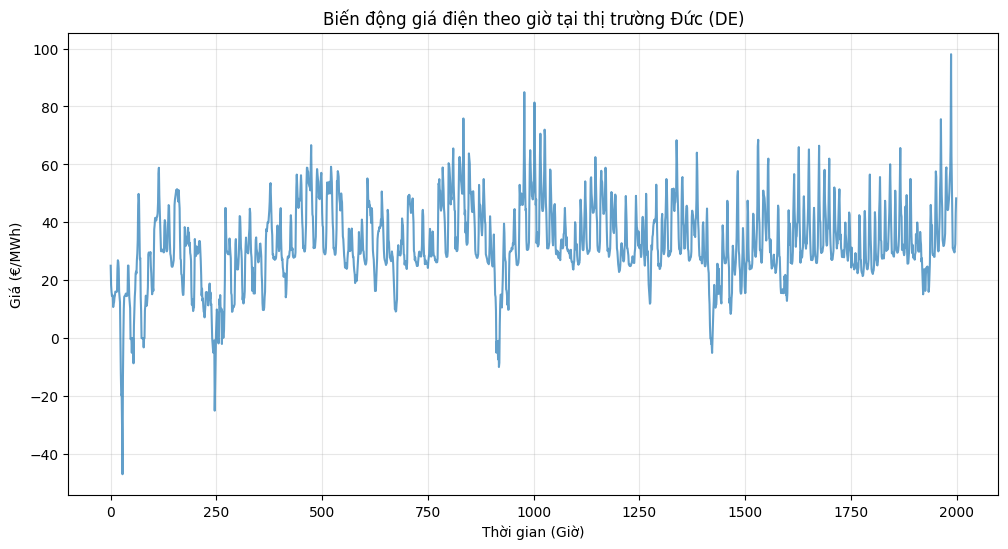

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chuyển hướng ra thư mục chứa dữ liệu tĩnh DE20
%cd /content/drive/MyDrive/Colab Notebooks/PEPF_bench/preprocessing/data

# 2. Đọc file dữ liệu
df_de = pd.read_csv('DE.csv')

# 3. Trích xuất Bảng thống kê mô tả (Mean, Std, Min, Max)
print("--- THỐNG KÊ MÔ TẢ GIÁ ĐIỆN THỊ TRƯỜNG ĐỨC (DE) ---")
print(df_de['Price'].describe())

# 4. Vẽ biểu đồ biến động giá điện để đưa vào Báo cáo/Slide
plt.figure(figsize=(12, 6))
# Giả sử cột dữ liệu thời gian là 'Date' hoặc thay bằng Index nếu file không có cột thời gian rõ ràng
plt.plot(df_de['Price'].values[:2000], alpha=0.7, color='C0') # Vẽ 2000 giờ đầu tiên để biểu đồ không bị rối
plt.title('Biến động giá điện theo giờ tại thị trường Đức (DE)')
plt.xlabel('Thời gian (Giờ)')
plt.ylabel('Giá (€/MWh)')
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
%cd '/content/drive/MyDrive/Colab Notebooks/PEPF_bench'
!python start_benchmark_DE.py include_covariates=True finetune=True

/content/drive/MyDrive/Colab Notebooks/PEPF_bench

=== Zero-shot Energy Price Forecasting Benchmark for DE Dataset ===
Model: moirai_1.1_R_small
Seed: 20
Context Length: 2048
Prediction Length: 24
Test Period: 2019-06-27 00:00:00 to 2021-01-01 00:00:00
Loading data from preprocessing/data/DE.csv
Loaded dataframe shape: (52608, 9)
Date range: 2015-01-01 00:00:00 to 2020-12-31 23:00:00
Preparing data for zero-shot prediction...
First Train Date: 2015-01-01 00:00:00
First Test Date: 2019-06-27 00:00:00
Last Test Date: 2020-12-31 23:00:00

Starting zero-shot prediction for 554 days...
Preparing model for day 0...
config.json: 100% 682/682 [00:00<00:00, 3.41MB/s]

model.safetensors: downloading bytes:  69% 38.0M/55.3M [00:01<00:00, 49.3MB/s, 2.17MB/s  ]
model.safetensors: downloading bytes: 100% 45.4M/45.4M [00:02<00:00, 22.0MB/s, 4.28MB/s  ]
model.safetensors: reconstructing file: 100% 55.3M/55.3M [00:02<00:00, 26.8MB/s, 5.27MB/s  ]
Predicting day 0/554...
Preparing model for day 1...
Pred

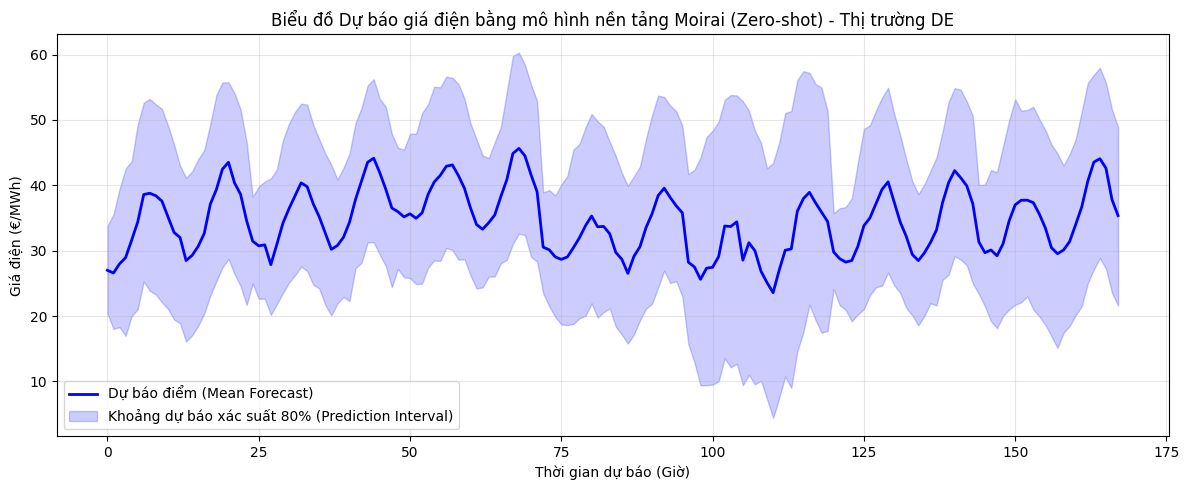

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu 1000 mẫu dự báo từ lần chạy mới nhất (_DE_1)
pred_path = '/content/drive/MyDrive/Colab Notebooks/PEPF_bench/benchmark_results/results_bench_moirai_zeroshot_seed_20_DE_1/samples_DE/DE_samples_seed_20.csv'
preds = pd.read_csv(pred_path).values

# 2. Tính toán giá trị trung bình (Mean Forecast) và khoảng tin cậy 80% (10th - 90th percentile)
mean_pred = np.mean(preds, axis=1)
lower_bound = np.percentile(preds, 10, axis=1)
upper_bound = np.percentile(preds, 90, axis=1)

# 3. Vẽ biểu đồ dự báo cho 168 giờ (Tương đương 1 tuần)
plt.figure(figsize=(12, 5))
plt.plot(mean_pred[:168], label='Dự báo điểm (Mean Forecast)', color='blue', linewidth=2)
plt.fill_between(range(168), lower_bound[:168], upper_bound[:168], color='blue', alpha=0.2, label='Khoảng dự báo xác suất 80% (Prediction Interval)')

plt.title('Biểu đồ Dự báo giá điện bằng mô hình nền tảng Moirai (Zero-shot) - Thị trường DE')
plt.xlabel('Thời gian dự báo (Giờ)')
plt.ylabel('Giá điện (€/MWh)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [2]:
!git init

!git remote add origin https://github.com/Kir4Kir4/MIDTERM-PTDL.git

!git branch -M main

hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/.git/


In [3]:
!git add .

In [4]:
!git commit -m "Complete end-to-end data pipeline: EDA, Regression, Classification (XGBoost), and Moirai integration"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@2f882c1aa2b6.(none)')


In [5]:
!git status

On branch main

No commits yet

Changes to be committed:
  (use "git rm --cached <file>..." to unstage)
	new file:   .config/.last_opt_in_prompt.yaml
	new file:   .config/.last_survey_prompt.yaml
	new file:   .config/.last_update_check.json
	new file:   .config/active_config
	new file:   .config/config_sentinel
	new file:   .config/configurations/config_default
	new file:   .config/default_configs.db
	new file:   .config/gce
	new file:   .config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
	new file:   .config/logs/2026.10.26/22.18.15.518759.log
	new file:   .config/logs/2026.10.26/22.18.38.571729.log
	new file:   .config/logs/2026.10.26/22.18.44.768076.log
	new file:   .config/logs/2026.10.26/22.18.45.880512.log
	new file:   .config/logs/2026.10.26/22.18.52.867204.log
	new file:   .config/logs/2026.10.26/22.18.53.588181.log
	new file:   sample_data/README.md
	new file:   sample_data/anscombe.json
	new file:   sample_data/california_housing_test.csv
	new file:   sampl